<a href="https://colab.research.google.com/github/reetikaChauhan/Road-Crack-Detection/blob/main/ResNetFineTuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import tensorflow as tf
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import layers
import os

Mounted at /content/drive


In [ ]:
OLD_MODEL_PATH = "/content/drive/MyDrive/models/resnet_original.h5"
# Root folder that now contains train/ and valid/
DATASET_ROOT = "/content/drive/MyDrive/BoundingBox_dataset_split"

TRAIN_DIR = os.path.join(DATASET_ROOT, "train")
VAL_DIR   = os.path.join(DATASET_ROOT, "val")
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

In [ ]:
!tar -cf /content/drive/MyDrive/BoundingBox_dataset_split.tar -C /content/drive/MyDrive BoundingBox_dataset_split
!cp /content/drive/MyDrive/BoundingBox_dataset_split.tar /content/
!rm -rf /content/BoundingBox_dataset_split
!tar -xf /content/BoundingBox_dataset_split.tar -C /content/
!ls -lah /content/BoundingBox_dataset_split | head


Streaming output truncated to the last 5000 lines.
tar: BoundingBox_dataset_split/val/negative/United_States_002453_x300_y600.jpg: file changed as we read it
tar: BoundingBox_dataset_split/val/negative/United_States_002455_x100_y600.jpg: file changed as we read it
tar: BoundingBox_dataset_split/val/negative/United_States_002458_x0_y600.jpg: file changed as we read it
tar: BoundingBox_dataset_split/val/negative/United_States_002461_x500_y500.jpg: file changed as we read it
tar: BoundingBox_dataset_split/val/negative/United_States_002461_x600_y400.jpg: file changed as we read it
tar: BoundingBox_dataset_split/val/negative/United_States_002461_x400_y500.jpg: file changed as we read it
tar: BoundingBox_dataset_split/val/negative/United_States_002461_x200_y400.jpg: file changed as we read it
tar: BoundingBox_dataset_split/val/negative/United_States_002461_x300_y600.jpg: file changed as we read it
tar: BoundingBox_dataset_split/val/negative/United_States_002461_x300_y500.jpg: file changed as

In [ ]:
!rsync -av "/content/drive/MyDrive/BoundingBox_dataset_split/" "/content/crack_dataset_split_local/"

Streaming output truncated to the last 5000 lines.
val/negative/United_States_001667_x200_y500.jpg
val/negative/United_States_001668_x300_y600.jpg
val/negative/United_States_001669_x200_y600.jpg
val/negative/United_States_001676_x0_y500.jpg
val/negative/United_States_001676_x200_y500.jpg
val/negative/United_States_001677_x200_y600.jpg
val/negative/United_States_001677_x600_y500.jpg
val/negative/United_States_001678_x300_y500.jpg
val/negative/United_States_001679_x0_y600.jpg
val/negative/United_States_001682_x200_y400.jpg
val/negative/United_States_001682_x200_y600.jpg
val/negative/United_States_001682_x300_y600.jpg
val/negative/United_States_001683_x100_y600.jpg
val/negative/United_States_001683_x200_y600.jpg
val/negative/United_States_001685_x200_y600.jpg
val/negative/United_States_001687_x600_y600.jpg
val/negative/United_States_001688_x0_y500.jpg
val/negative/United_States_001690_x0_y500.jpg
val/negative/United_States_001690_x400_y600.jpg
val/negative/United_States_001690_x500_y500.j

In [ ]:
!ls /content/crack_dataset_split_local

In [ ]:
#DATASET_ROOT = "/content/crack_dataset_split_local"
DATASET_ROOT = "/content/BoundingBox_dataset_split/"
TRAIN_DIR = DATASET_ROOT + "/train"
VAL_DIR   = DATASET_ROOT + "/val"


In [ ]:
resnet_model = tf.keras.models.load_model(OLD_MODEL_PATH)
resnet_model.summary()

# The first layer should be the ResNet50 backbone you added originally
base_model = resnet_model.layers[0]
print("Backbone layer name:", base_model.name)
print("Total backbone layers:", len(base_model.layers))

# ============================================
# 4. Build train & valid datasets
# ============================================
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Class names:", train_ds.class_names)



Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,637,315 (93.98 MB)

 Trainable params: 1,049,601 (4.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

 Optimizer params: 2 (12.00 B)

Backbone layer name: resnet50
Total backbone layers: 175
Found 24760 files belonging to 2 classes.
Found 6206 files belonging to 2 classes.
Class names: ['negative', 'positive']


In [ ]:
# Rescale to 0–1 (like you intended)
rescale_layer = tf.keras.layers.Rescaling(1./255)

def preprocess(image, label):
    image = tf.cast(image, tf.float32)
    image = rescale_layer(image)
    return image, label

train_ds = train_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds   = val_ds.map(preprocess,   num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

In [ ]:
base_model = resnet_model.layers[0]
print("Backbone name:", base_model.name)

# ------- Phase 1: head-only training on new split --------
base_model.trainable = False

resnet_model.compile(
    optimizer=Adam(1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("\n Phase 1: training head only...")
history_head = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50
)

# ------- Phase 2: fine-tune some of ResNet --------
base_model.trainable = True

fine_tune_from = max(0, len(base_model.layers) - 40)
for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

resnet_model.compile(
    optimizer=Adam(1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("\n Phase 2: fine-tuning backbone...")
history_ft = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50
)

FINE_TUNED_PATH = "/content/drive/MyDrive/models/resnet_finetuned_crack.h5"
resnet_model.save(FINE_TUNED_PATH)
print("\n Saved fine-tuned model to:", FINE_TUNED_PATH)


Backbone name: resnet50

 Phase 1: training head only...
Epoch 1/50
774/774 ━━━━━━━━━━━━━━━━━━━━ 119s 139ms/step - accuracy: 0.5461 - loss: 0.7077 - val_accuracy: 0.5844 - val_loss: 0.6784
Epoch 2/50
774/774 ━━━━━━━━━━━━━━━━━━━━ 82s 106ms/step - accuracy: 0.5858 - loss: 0.6780 - val_accuracy: 0.5844 - val_loss: 0.6765
Epoch 3/50
774/774 ━━━━━━━━━━━━━━━━━━━━ 78s 101ms/step - accuracy: 0.5863 - loss: 0.6774 - val_accuracy: 0.5844 - val_loss: 0.6750
Epoch 4/50
774/774 ━━━━━━━━━━━━━━━━━━━━ 83s 107ms/step - accuracy: 0.5861 - loss: 0.6763 - val_accuracy: 0.5844 - val_loss: 0.6752
Epoch 5/50
774/774 ━━━━━━━━━━━━━━━━━━━━ 77s 100ms/step - accuracy: 0.5866 - loss: 0.6755 - val_accuracy: 0.5844 - val_loss: 0.6738
Epoch 6/50
774/774 ━━━━━━━━━━━━━━━━━━━━ 78s 100ms/step - accuracy: 0.5858 - loss: 0.6760 - val_accuracy: 0.5844 - val_loss: 0.6737
Epoch 7/50
774/774 ━━━━━━━━━━━━━━━━━━━━ 77s 100ms/step - accuracy: 0.5856 - loss: 0.6754 - val_accuracy: 0.5844 - val_loss: 0.6727
Epoch 8/50
774/774 ━━━━━━


 Saved fine-tuned model to: /content/drive/MyDrive/models/resnet_finetuned_crack.h5


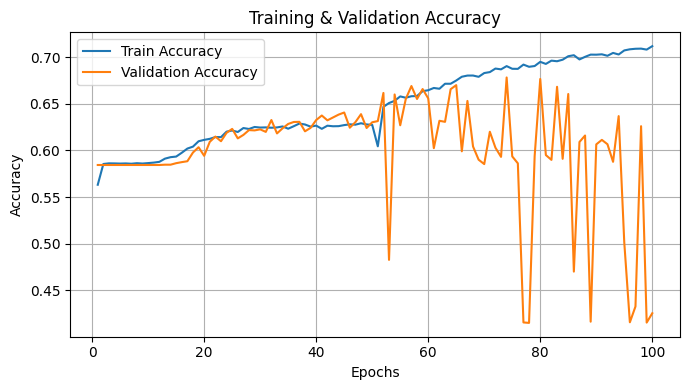

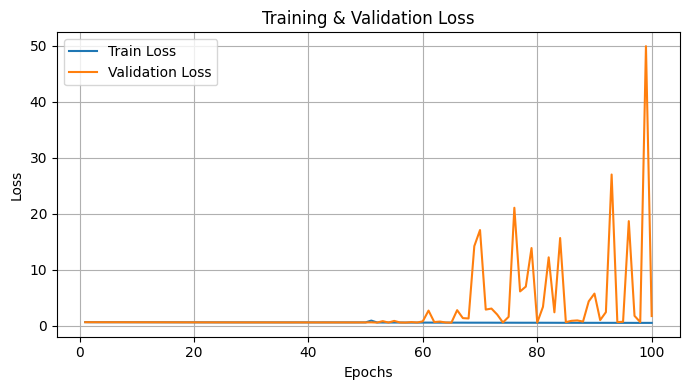

In [ ]:
import matplotlib.pyplot as plt

# ---- Combine histories from Phase 1 and Phase 2 ----
def combine_histories(h1, h2):
    history = {}
    for key in h1.history.keys():
        # Some keys may not be in h2
        history[key] = h1.history[key] + h2.history.get(key, [])
    return history

combined_history = combine_histories(history_head, history_ft)

epochs = range(1, len(combined_history["loss"]) + 1)

# ----------------- Plot Accuracy -----------------
plt.figure(figsize=(7,4))
plt.plot(epochs, combined_history["accuracy"], label="Train Accuracy")
plt.plot(epochs, combined_history["val_accuracy"], label="Validation Accuracy")
plt.title("Training & Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ----------------- Plot Loss -----------------
plt.figure(figsize=(7,4))
plt.plot(epochs, combined_history["loss"], label="Train Loss")
plt.plot(epochs, combined_history["val_loss"], label="Validation Loss")
plt.title("Training & Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
from matplotlib import pyplot as plt
from sklearn.metrics import confusion_matrix , classification_report
import pandas as pd
def print_confusion_matrix(confusion_matrix, class_names, figsize = (10,7), fontsize=14):
    """Prints a confusion matrix, as returned by sklearn.metrics.confusion_matrix, as a heatmap.

    Arguments
    ---------
    confusion_matrix: numpy.ndarray
        The numpy.ndarray object returned from a call to sklearn.metrics.confusion_matrix.
        Similarly constructed ndarrays can also be used.
    class_names: list
        An ordered list of class names, in the order they index the given confusion matrix.
    figsize: tuple
        A 2-long tuple, the first value determining the horizontal size of the ouputted figure,
        the second determining the vertical size. Defaults to (10,7).
    fontsize: int
        Font size for axes labels. Defaults to 14.

    Returns
    -------
    matplotlib.figure.Figure
        The resulting confusion matrix figure
    """
    df_cm = pd.DataFrame(
        confusion_matrix, index=class_names, columns=class_names,
    )
    fig = plt.figure(figsize=figsize)
    try:
        heatmap = sns.heatmap(df_cm, annot=True, fmt="d")
    except ValueError:
        raise ValueError("Confusion matrix values must be integers.")
    heatmap.yaxis.set_ticklabels(heatmap.yaxis.get_ticklabels(), rotation=0, ha='right', fontsize=fontsize)
    heatmap.xaxis.set_ticklabels(heatmap.xaxis.get_ticklabels(), rotation=45, ha='right', fontsize=fontsize)
    plt.ylabel('Truth')
    plt.xlabel('Prediction')


Found 399 files belonging to 2 classes.
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 583ms/step
Classification Report:
               precision    recall  f1-score   support

         0.0       0.50      0.97      0.66       200
         1.0       0.50      0.03      0.06       199

    accuracy                           0.50       399
   macro avg       0.50      0.50      0.36       399
weighted avg       0.50      0.50      0.36       399



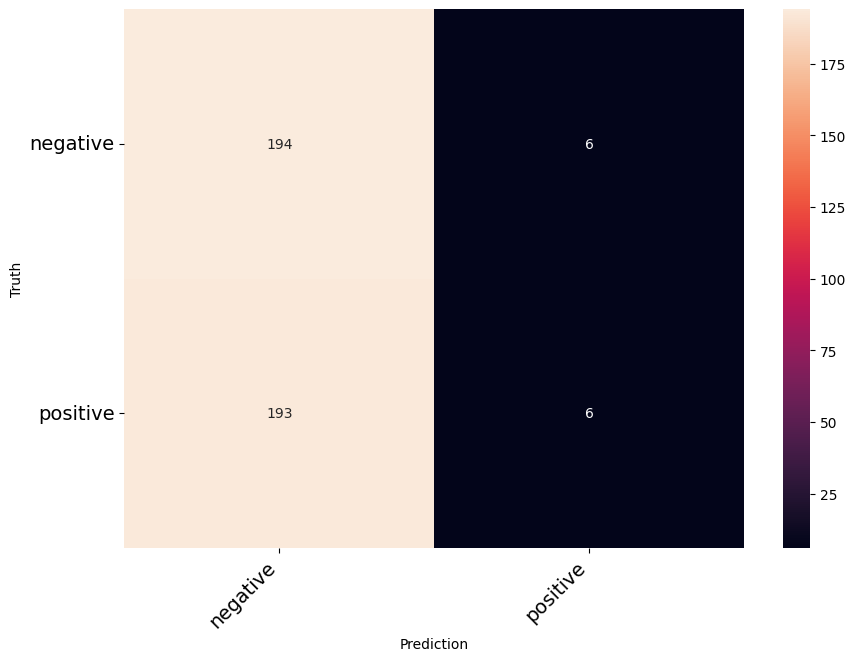

In [ ]:
import tensorflow as tf
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix

test_dir = "/content/drive/My Drive/Crops/"

test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    shuffle=False,  # No shuffling for evaluation
    batch_size=32,
    image_size=(224, 224),  # ResNet50 expects 224x224 images
    label_mode='binary'  # Change to 'categorical' for multi-class classification
)
class_names = test_dataset.class_names
# Get truth labels
y_true = []
for _, labels in test_dataset:
    y_true.extend(labels.numpy())
y_true = np.array(y_true)

# Get predictions
y_pred_prob = resnet_model.predict(test_dataset)  # Outputs probabilities between 0 and 1
y_pred = (y_pred_prob > 0.5).astype("int32")  # Convert to 0 or 1 based on threshold


# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Print confusion matrix
print_confusion_matrix(cm, class_names)

print("Classification Report:\n", classification_report(y_true, y_pred))


In [ ]:
loss, accuracy = resnet_model.evaluate(test_dataset)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 244ms/step - accuracy: 0.7746 - loss: 31.0933
Test Loss: 69.1690
Test Accuracy: 0.5013


In [ ]:
import os
import tensorflow as tf
from tensorflow.keras.optimizers import Adam

# ==============================
# 1. PATHS – EDIT THESE
# ==============================
MODEL_PATH = "/content/drive/MyDrive/models/resnet_original.h5"  # model from Drive
DATASET_ROOT = "/content/BoundingBox_dataset_split/"                     # local data

TRAIN_DIR = os.path.join(DATASET_ROOT, "train")
VAL_DIR   = os.path.join(DATASET_ROOT, "val")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# ==============================
# 2. Load model from Drive
# ==============================
resnet_model = tf.keras.models.load_model(MODEL_PATH)
resnet_model.summary()

# ResNet backbone is the first layer
base_model = resnet_model.layers[0]
print("Backbone name:", base_model.name)

# ==============================
# 3. Load TRAIN + VAL datasets from local
# ==============================
train_raw_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_raw_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print("Classes:", train_raw_ds.class_names)

# Preprocessing: Rescaling 1/255
rescale_layer = tf.keras.layers.Rescaling(1./255)

def preprocess(image, label):
    image = tf.cast(image, tf.float32)
    image = rescale_layer(image)
    return image, label

train_ds = train_raw_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds   = val_raw_ds.map(preprocess,   num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# ==============================
# 4. OPEN THE ENTIRE MODEL
# ==============================
base_model.trainable = True

# Make absolutely everything trainable
for layer in resnet_model.layers:
    layer.trainable = True

# ==============================
# 5. Recompile with LOW LR
# ==============================
resnet_model.compile(
    optimizer=Adam(learning_rate=1e-5),   # LOW learning rate for full fine-tuning
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# ==============================
# 6. Train for 50 epochs (NO EARLY STOPPING)
# ==============================
history_full = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50
)

# ==============================
# 7. Save the fully fine-tuned model
# ==============================
FINAL_MODEL_PATH = "/content/drive/MyDrive/models/resnet_full_open_finetuned.h5"
resnet_model.save(FINAL_MODEL_PATH)

print("\n Saved fully-opened fine-tuned model to:", FINAL_MODEL_PATH)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,637,315 (93.98 MB)

 Trainable params: 1,049,601 (4.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

 Optimizer params: 2 (12.00 B)

Backbone name: resnet50
Found 24760 files belonging to 2 classes.
Found 6206 files belonging to 2 classes.
Classes: ['negative', 'positive']
Epoch 1/50
774/774 ━━━━━━━━━━━━━━━━━━━━ 344s 351ms/step - accuracy: 0.6223 - loss: 4.3146 - val_accuracy: 0.4270 - val_loss: 34.7628
Epoch 2/50
774/774 ━━━━━━━━━━━━━━━━━━━━ 237s 307ms/step - accuracy: 0.6863 - loss: 0.8842 - val_accuracy: 0.7153 - val_loss: 0.6694
Epoch 3/50
774/774 ━━━━━━━━━━━━━━━━━━━━ 236s 305ms/step - accuracy: 0.7270 - loss: 0.5835 - val_accuracy: 0.7248 - val_loss: 0.5868
Epoch 4/50
774/774 ━━━━━━━━━━━━━━━━━━━━ 237s 306ms/step - accuracy: 0.7475 - loss: 0.5313 - val_accuracy: 0.7409 - val_loss: 0.5552
Epoch 5/50
774/774 ━━━━━━━━━━━━━━━━━━━━ 237s 306ms/step - accuracy: 0.7663 - loss: 0.4879 - val_accuracy: 0.7472 - val_loss: 0.5463
Epoch 6/50
774/774 ━━━━━━━━━━━━━━━━━━━━ 236s 306ms/step - accuracy: 0.7867 - loss: 0.4617 - val_accuracy: 0.7504 - val_loss: 0.5464
Epoch 7/50
774/774 ━━━━━━━━━━━━━━━━━━━━ 237s 306ms/step - accuracy


 Saved fully-opened fine-tuned model to: /content/drive/MyDrive/models/resnet_full_open_finetuned.h5


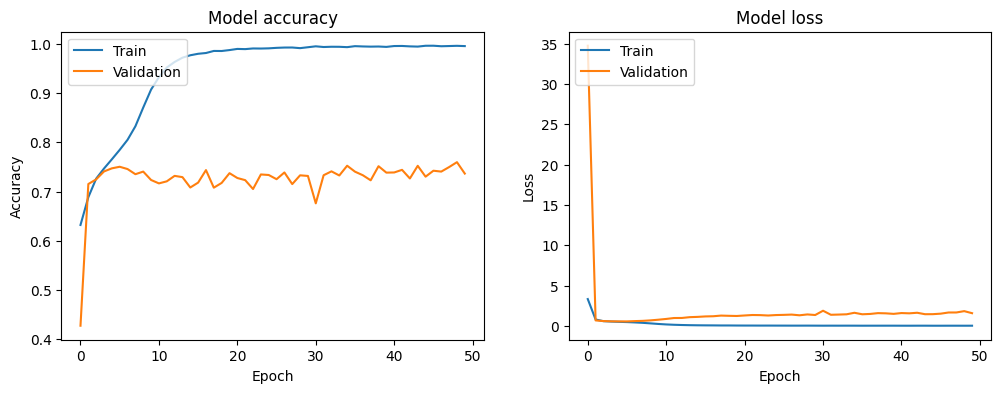

In [ ]:
import matplotlib.pyplot as plt

# Assuming you have the 'history' object from your model training

# Plot training & validation accuracy values
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_full.history['accuracy'])
plt.plot(history_full.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history_full.history['loss'])
plt.plot(history_full.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
from matplotlib import pyplot as plt
from sklearn.metrics import confusion_matrix , classification_report
import pandas as pd
def print_confusion_matrix(confusion_matrix, class_names, figsize = (10,7), fontsize=14):
    """Prints a confusion matrix, as returned by sklearn.metrics.confusion_matrix, as a heatmap.

    Arguments
    ---------
    confusion_matrix: numpy.ndarray
        The numpy.ndarray object returned from a call to sklearn.metrics.confusion_matrix.
        Similarly constructed ndarrays can also be used.
    class_names: list
        An ordered list of class names, in the order they index the given confusion matrix.
    figsize: tuple
        A 2-long tuple, the first value determining the horizontal size of the ouputted figure,
        the second determining the vertical size. Defaults to (10,7).
    fontsize: int
        Font size for axes labels. Defaults to 14.

    Returns
    -------
    matplotlib.figure.Figure
        The resulting confusion matrix figure
    """
    df_cm = pd.DataFrame(
        confusion_matrix, index=class_names, columns=class_names,
    )
    fig = plt.figure(figsize=figsize)
    try:
        heatmap = sns.heatmap(df_cm, annot=True, fmt="d")
    except ValueError:
        raise ValueError("Confusion matrix values must be integers.")
    heatmap.yaxis.set_ticklabels(heatmap.yaxis.get_ticklabels(), rotation=0, ha='right', fontsize=fontsize)
    heatmap.xaxis.set_ticklabels(heatmap.xaxis.get_ticklabels(), rotation=45, ha='right', fontsize=fontsize)
    plt.ylabel('Truth')
    plt.xlabel('Prediction')


Found 399 files belonging to 2 classes.
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 122ms/step
Classification Report:
               precision    recall  f1-score   support

         0.0       0.00      0.00      0.00       200
         1.0       0.50      1.00      0.67       199

    accuracy                           0.50       399
   macro avg       0.25      0.50      0.33       399
weighted avg       0.25      0.50      0.33       399



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


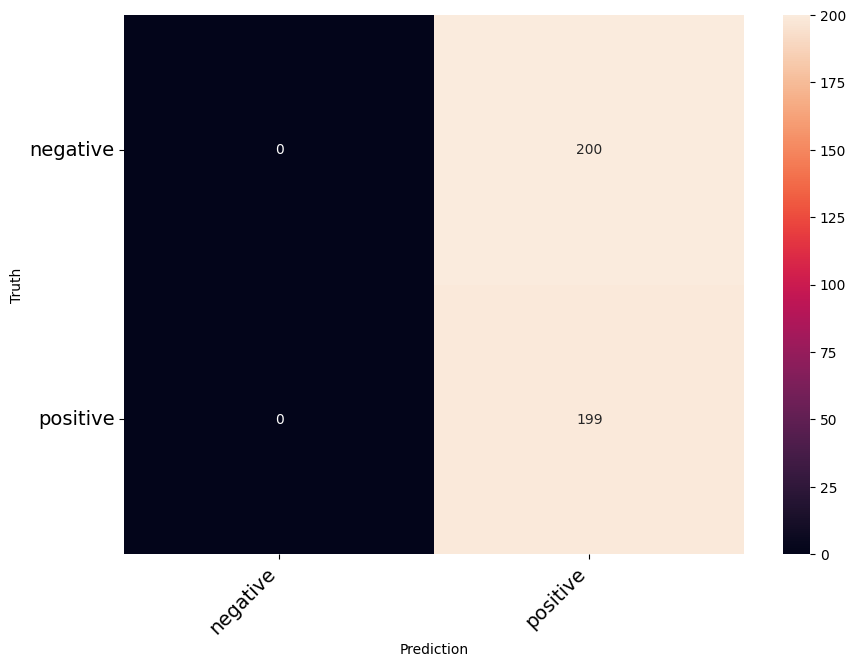

In [ ]:
import tensorflow as tf
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix

test_dir = "/content/drive/My Drive/Crops/"

test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    shuffle=False,  # No shuffling for evaluation
    batch_size=32,
    image_size=(224, 224),  # ResNet50 expects 224x224 images
    label_mode='binary'  # Change to 'categorical' for multi-class classification
)
class_names = test_dataset.class_names
# Get truth labels
y_true = []
for _, labels in test_dataset:
    y_true.extend(labels.numpy())
y_true = np.array(y_true)

# Get predictions
y_pred_prob = resnet_model.predict(test_dataset)  # Outputs probabilities between 0 and 1
y_pred = (y_pred_prob > 0.5).astype("int32")  # Convert to 0 or 1 based on threshold


# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Print confusion matrix
print_confusion_matrix(cm, class_names)

print("Classification Report:\n", classification_report(y_true, y_pred))


In [ ]:
# Evaluate the loaded model with the test dataset
loss, accuracy = resnet_model.evaluate(test_dataset)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 285ms/step - accuracy: 0.2082 - loss: 41688.2305
Test Loss: 26547.3125
Test Accuracy: 0.4987


In [ ]:
import tensorflow as tf

MODEL_PATH = "/content/drive/MyDrive/models/resnet_full_open_finetuned.h5"
resnet_model = tf.keras.models.load_model(MODEL_PATH)
last_layer = resnet_model.layers[-1]
print("Last layer:", last_layer.name)
print("Last layer config:")
print(last_layer.get_config())


Last layer: dense_1
Last layer config:
{'name': 'dense_1', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'units': 1, 'activation': 'sigmoid', 'use_bias': True, 'kernel_initializer': {'module': 'keras.initializers', 'class_name': 'GlorotUniform', 'config': {'seed': None}, 'registered_name': None}, 'bias_initializer': {'module': 'keras.initializers', 'class_name': 'Zeros', 'config': {}, 'registered_name': None}, 'kernel_regularizer': None, 'bias_regularizer': None, 'kernel_constraint': None, 'bias_constraint': None}


In [ ]:
import os
import tensorflow as tf
from tensorflow.keras.optimizers import Adam

# ==============================
# 1. PATHS – EDIT THESE
# ==============================
MODEL_PATH = "/content/drive/MyDrive/models/resnet_original.h5"  # model from Drive
DATASET_ROOT = "/content/BoundingBox_dataset_split/"                     # local data

TRAIN_DIR = os.path.join(DATASET_ROOT, "train")
VAL_DIR   = os.path.join(DATASET_ROOT, "val")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# ==============================
# 2. Load model from Drive
# ==============================
resnet_model = tf.keras.models.load_model(MODEL_PATH)
resnet_model.summary()

# ResNet backbone is the first layer
base_model = resnet_model.layers[0]
print("Backbone name:", base_model.name)

# ==============================
# 3. Load TRAIN + VAL datasets from local
# ==============================
train_raw_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_raw_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print("Classes:", train_raw_ds.class_names)

# Preprocessing: Rescaling 1/255
rescale_layer = tf.keras.layers.Rescaling(1./255)

def preprocess(image, label):
    image = tf.cast(image, tf.float32)
    image = rescale_layer(image)
    return image, label

train_ds = train_raw_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds   = val_raw_ds.map(preprocess,   num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)


base_model = resnet_model.layers[0]
print("Backbone name:", base_model.name)

# ------- Phase 1: head-only training  --------
base_model.trainable = False

resnet_model.compile(
    optimizer=Adam(1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("\n Phase : training head only...")
history_head = resnet_model.fit(
    train_raw_ds,
    validation_data = val_raw_ds,
    epochs=100
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,637,315 (93.98 MB)

 Trainable params: 1,049,601 (4.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

 Optimizer params: 2 (12.00 B)

Backbone name: resnet50
Found 24760 files belonging to 2 classes.
Found 6206 files belonging to 2 classes.
Classes: ['negative', 'positive']
Backbone name: resnet50

 Phase : training head only...
Epoch 1/100
774/774 ━━━━━━━━━━━━━━━━━━━━ 107s 121ms/step - accuracy: 0.6174 - loss: 2.2231 - val_accuracy: 0.7092 - val_loss: 0.5760
Epoch 2/100
774/774 ━━━━━━━━━━━━━━━━━━━━ 122s 104ms/step - accuracy: 0.6997 - loss: 0.5888 - val_accuracy: 0.7249 - val_loss: 0.5494
Epoch 3/100
774/774 ━━━━━━━━━━━━━━━━━━━━ 80s 103ms/step - accuracy: 0.7229 - loss: 0.5549 - val_accuracy: 0.7309 - val_loss: 0.5394
Epoch 4/100
774/774 ━━━━━━━━━━━━━━━━━━━━ 84s 109ms/step - accuracy: 0.7324 - loss: 0.5412 - val_accuracy: 0.7372 - val_loss: 0.5353
Epoch 5/100
774/774 ━━━━━━━━━━━━━━━━━━━━ 80s 103ms/step - accuracy: 0.7373 - loss: 0.5321 - val_accuracy: 0.7369 - val_loss: 0.5328
Epoch 6/100
774/774 ━━━━━━━━━━━━━━━━━━━━ 80s 103ms/step - accuracy: 0.7394 - loss: 0.5280 - val_accuracy: 0.7380 - val_loss: 0.5284
Epoch 7/1